# 3. Describe your own detector

A CMS chamber comes from the XML; anything else is written as a spec. There are
three levels of verbosity for the same document, and this notebook uses all
three:

1. the short constructors `make_layer`, `make_superlayer`, `make_station`;
2. the plain dataclasses (`StationSpec`, `SuperLayerSpec`, `LayerSpec`, ...);
3. a JSON file, which is what you keep in the repository.

The example is a test-beam chamber: two super layers, four layers each, 20 cm
pitch, the second super layer turned by 90 degrees like a CMS middle one.

In [1]:
%matplotlib inline
from mpldts.geometry.constructors import make_layer, make_station, make_superlayer
from mpldts.geometry.specs import Box, CellGrid, Pose

PITCH = 20.0

def layers():
    return [
        make_layer(number,
                   CellGrid(pitch=PITCH, count=8, shape=Box(PITCH, 100.0, 1.3),
                            material="GasMixture"),
                   pose=Pose.translated(0.0, 0.0, (number - 2.5) * 2.0))
        for number in range(1, 5)
    ]

super_layers = [
    make_superlayer(number, layers(),
                    pose=Pose.rotated_z(90.0 if number == 2 else 0.0,
                                        (0.0, 0.0, (number - 1.5) * 9.5)))
    for number in (1, 2)
]
chamber = make_station("TB-1", super_layers, shape=Box(8 * PITCH, 100.0, 9.5 + 8.8))
print(chamber.name, [sl.number for sl in chamber.super_layers], chamber.material)

TB-1 [1, 2] G4_AIR


## From a station to a detector

`DetectorSpec` groups stations, gives them a pose and can hold structural solids
(the yoke, the table) that are data only - they are never turned into nodes.

In [2]:
from mpldts.geometry import Station, build_detector
from mpldts.geometry.specs import DetectorSpec, StructureSpec, validate

detector = DetectorSpec(
    name="test beam",
    pose=Pose.identity(),
    stations=[
        make_station("TB-1", super_layers, shape=chamber.shape,
                     pose=Pose.translated(-40.0, 0.0, 0.0)),
        make_station("TB-2", super_layers, shape=chamber.shape,
                     pose=Pose.rotated_z(90.0, (40.0, 0.0, 0.0))),
    ],
    structure=[StructureSpec("Table", Pose.translated(0.0, 0.0, -80.0),
                             Box(200.0, 200.0, 10.0))],
)
validate(detector)
node = build_detector(detector)
print("stations:", [child.name for child in node.children])
print("structure is data, not a node:", "Table" not in [child.name for child in node.children])

stations: ['TB-1', 'TB-2']
structure is data, not a node: True


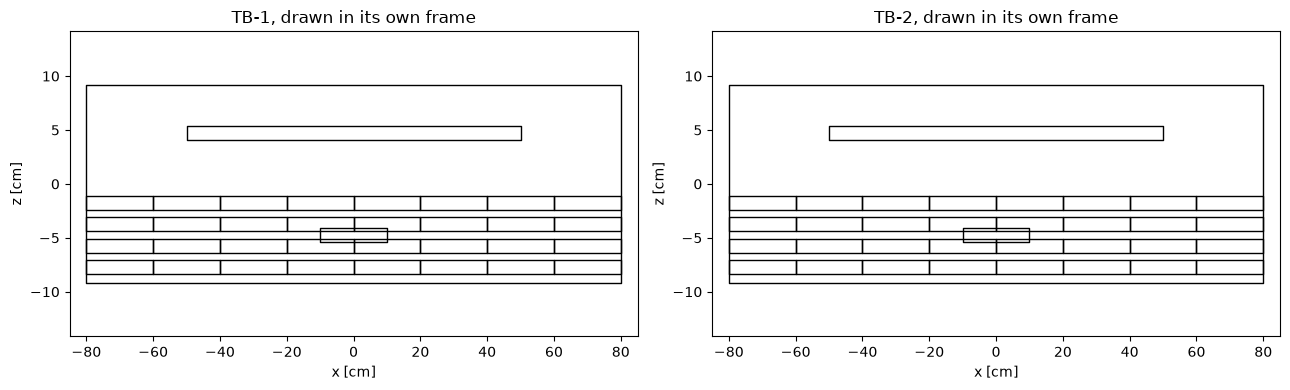

In [3]:
import matplotlib.pyplot as plt
from mpldts.patches import DTStationPatch

figure, axes = plt.subplots(1, 2, figsize=(13, 4))
for axis, spec in zip(axes, detector.stations):
    station = Station.from_spec(spec)
    width, height, length = station.bounds
    x, y, z = station.local_center
    DTStationPatch(station, axis, faceview="phi", local=True)
    axis.set_xlim(x - width / 2 - 5, x + width / 2 + 5)
    axis.set_ylim(z - height / 2 - 5, z + height / 2 + 5)
    axis.set_title("%s, drawn in its own frame" % station.name)
    axis.set_xlabel("x [cm]")
    axis.set_ylabel("z [cm]")
figure.tight_layout()

## Keep it as a JSON document

A spec serialises to a document that validates on the way back in, so the
geometry of a custom detector can live in the repository next to the code.

In [4]:
import json
from mpldts.geometry.serialize import from_json, to_json

text = to_json(detector)
restored = from_json(text)
print(len(text), "bytes of JSON;", len(restored.stations), "stations back")
print(json.dumps(json.loads(text)["stations"][0], indent=2)[:500])

20003 bytes of JSON; 2 stations back
{
  "name": "TB-1",
  "pose": {
    "rotation": [
      [
        1.0,
        0.0,
        0.0
      ],
      [
        0.0,
        1.0,
        0.0
      ],
      [
        0.0,
        0.0,
        1.0
      ]
    ],
    "translation": [
      -40.0,
      0.0,
      0.0
    ]
  },
  "shape": {
    "kind": "box",
    "dx": 160.0,
    "dy": 100.0,
    "dz": 18.3
  },
  "material": "G4_AIR",
  "super_layers": [
    {
      "number": 1,
      "pose": {
        "rotation": [
          [
        


## Export it for Geant4

`iter_volume_placements` walks the node tree and `TgSink` writes the `.tg` text
that the Geant4 simulation reads with `G4tgbVolumeMgr`. One solid per station,
one placement per cell.

In [5]:
from mpldts.export import TgSink, export_volumes, iter_volume_placements

print(len(list(iter_volume_placements(node))), "placements")

import io
stream = io.StringIO()
export_volumes(node, TgSink(stream))
print(stream.getvalue()[:600])

130 placements
// mplDTs .tg export: test_beam

:SOLID Solid_TB-1 BOX 80.000000*cm 50.000000*cm 9.150000*cm
:VOLU TB-1 Solid_TB-1 G4_AIR

:PLACE TB-1 1 world R0 -40.000000*cm 0.000000*cm 0.000000*cm
:SOLID Solid_DriftCell_TB-1_SL1 BOX 10.000000*cm 50.000000*cm 0.650000*cm
:VOLU DriftCell_TB-1_SL1 Solid_DriftCell_TB-1_SL1 GasMixture

:PLACE DriftCell_TB-1_SL1 1 TB-1 R0 -70.000000*cm 0.000000*cm -7.750000*cm
:PLACE DriftCell_TB-1_SL1 2 TB-1 R0 -50.000000*cm 0.000000*cm -7.750000*cm
:PLACE DriftCell_TB-1_SL1 3 TB-1 R0 -30.000000*cm 0.000000*cm -7.750000*cm
:PLACE DriftCell_TB-1_SL1 4 TB-1 R0 -10.000000*cm 0.000


The volume names in that block are a contract: the C++ `StationSD` parses the
wheel out of `MB0_W-2_SE1_ST1`, which is why the minus sign survives the
sanitiser. Do not rename them without reading the naming page.

What next:

- `docs/concepts/model.rst` - why specs, nodes and views are separate;
- `docs/howto/geant4.rst` - how the `.tg` file is consumed;
- `docs/about/roadmap.rst` - the GDML backend is an idea, not a feature yet.